In [1]:
setwd("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data") # change to local tutorial directory

library(ArchR)
library(dplyr)
#library(ggpubr)
library(grid)
#library(harmony)
library(knitr)
#library(magick)
library(Matrix)
#library(patchwork)
#library(pheatmap)
#library(purrr)
#library(rmarkdown)
library(Seurat)


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

In [2]:
set.seed(1)

### Load ArchR object

In [3]:
print(Sys.time())
#proj <- readRDS("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/processed/r_objects/kidney7.rds")
proj <- loadArchRProject(path = "/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/processed/scATAC/r_objects/Save-Project1")

[1] "2025-12-10 13:39:51 CET"


Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .____

In [5]:
proj@cellColData

DataFrame with 55206 rows and 16 columns
                                        Sample TSSEnrichment ReadsInTSS
                                         <Rle>       <array>    <array>
Healthy_63079#GACAGTGCACCACTGT-1 Healthy_63079         6.205      32938
Healthy_63079#GAGTTAGCACATTGGC-1 Healthy_63079         6.162      24582
Healthy_63079#GAACAGGCACAAGCTA-1 Healthy_63079          5.07      16319
Healthy_63079#GACAGTGCACAAGCTA-1 Healthy_63079         5.799      18521
Healthy_63079#CCTCTATCAAGACGGA-1 Healthy_63079         5.186      13849
...                                        ...           ...        ...
Healthy_63055#TAGGATGACGGATTGC-1 Healthy_63055        13.333        303
Healthy_63055#AATGTTGCGCCACATA-1 Healthy_63055         6.912        185
Healthy_63055#GTCGTAGACCGTGAGA-1 Healthy_63055         7.085        229
Healthy_63055#ACGTATCAAGAGTCAA-1 Healthy_63055         5.644        171
Healthy_63055#AGAGTCAAATCATTCC-1 Healthy_63055        12.601        280
                       

### Dimentsion Reduction

In [6]:
proj <- addIterativeLSI(
			    ArchRProj = proj,
			    useMatrix = "PeakMatrix",
			    name = "IterativeLSI",
			    iterations = 4,
			    clusterParams = list(
						 resolution = c(0.8, 1.0, 1.5),
                         #resolution = c(0.1),
						 sampleCells = 10000,
						 n.start = 10
					    ),
			    varFeatures = 25000,
			    dimsToUse = 1:30,
			    force = TRUE,
			    seed = 1
)

proj <- addHarmony(
  ArchRProj = proj,
 reducedDims = "IterativeLSI",
name = "Harmony",
groupBy = "Sample",
  force = TRUE
)

Checking Inputs...

ArchR logging to : ArchRLogs/ArchR-addIterativeLSI-4703a7cc8d891-Date-2025-12-10_Time-13-55-00.720358.log
If there is an issue, please report to github with logFile!

2025-12-10 13:55:04.221627 : Computing Total Across All Features, 0.025 mins elapsed.

2025-12-10 13:55:09.54896 : Computing Top Features, 0.114 mins elapsed.

###########
2025-12-10 13:55:10.146427 : Running LSI (1 of 4) on Top Features, 0.124 mins elapsed.
###########

2025-12-10 13:55:10.226819 : Sampling Cells (N = 10004) for Estimated LSI, 0.125 mins elapsed.

2025-12-10 13:55:10.232734 : Creating Sampled Partial Matrix, 0.125 mins elapsed.

2025-12-10 13:55:32.666768 : Computing Estimated LSI (projectAll = FALSE), 0.499 mins elapsed.

2025-12-10 13:56:09.900645 : Identifying Clusters, 1.12 mins elapsed.

2025-12-10 13:56:24.621559 : Identified 8 Clusters, 1.365 mins elapsed.

2025-12-10 13:56:24.656308 : Saving LSI Iteration, 1.366 mins elapsed.

2025-12-10 13:56:47.800879 : Creating Cluster Matr

In [12]:
proj <- addClusters(
  input = proj,
  reducedDims = "Harmony",
  method = "Seurat",
  name = c("Clusters"),
  resolution = c(0.8),
  force = TRUE
)

proj <- addClusters(
  input = proj,
  reducedDims = "Harmony",
  method = "Seurat",
  name = c("Clusters1"),
  resolution = c(1.0),
  force = TRUE
)

proj <- addClusters(
  input = proj,
  reducedDims = "Harmony",
  method = "Seurat",
  name = c("Clusters2"),
  resolution = c(1.5),
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addClusters-4703a79bf4057-Date-2025-12-10_Time-14-13-30.174725.log
If there is an issue, please report to github with logFile!

Overriding previous entry for Clusters

2025-12-10 14:13:31.213124 : Running Seurats FindClusters (Stuart et al. Cell 2019), 0.002 mins elapsed.

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 55206
Number of edges: 1024565

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8006
Number of communities: 94
Elapsed time: 6 seconds


82 singletons identified. 12 final clusters.

2025-12-10 14:14:34.449216 : Testing Biased Clusters, 1.056 mins elapsed.

2025-12-10 14:14:34.500667 : Testing Outlier Clusters, 1.057 mins elapsed.

2025-12-10 14:14:34.510533 : Assigning Outlier Clusters (n = 1, nOutlier < 5 cells) to Neighbors, 1.057 mins elapsed.

2025-12-10 14:14:34.555181 : Assigning Cluster Names to 11 Clusters, 1.058 mins elapsed.

2025-12-10 14:14:34.689191 : Finished addClusters, 1.06 mins elapsed.

ArchR logging to : ArchRLogs/ArchR-addClusters-4703a57c7880f-Date-2025-12-10_Time-14-14-34.696929.log
If there is an issue, please report to github with logFile!

2025-12-10 14:14:35.893312 : Running Seurats FindClusters (Stuart et al. Cell 2019), 0.001 mins elapsed.

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 55206
Number of edges: 1024565

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7814
Number of communities: 95
Elapsed time: 7 seconds


82 singletons identified. 13 final clusters.

2025-12-10 14:15:41.223975 : Testing Biased Clusters, 1.09 mins elapsed.

2025-12-10 14:15:41.253404 : Testing Outlier Clusters, 1.091 mins elapsed.

2025-12-10 14:15:41.261916 : Assigning Outlier Clusters (n = 1, nOutlier < 5 cells) to Neighbors, 1.091 mins elapsed.

2025-12-10 14:15:41.306973 : Assigning Cluster Names to 12 Clusters, 1.092 mins elapsed.

2025-12-10 14:15:41.394218 : Finished addClusters, 1.093 mins elapsed.

ArchR logging to : ArchRLogs/ArchR-addClusters-4703a71a8a712-Date-2025-12-10_Time-14-15-41.40213.log
If there is an issue, please report to github with logFile!

2025-12-10 14:15:42.268689 : Running Seurats FindClusters (Stuart et al. Cell 2019), 0.001 mins elapsed.

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 55206
Number of edges: 1024565

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7356
Number of communities: 98
Elapsed time: 7 seconds


82 singletons identified. 16 final clusters.

2025-12-10 14:16:48.868191 : Testing Biased Clusters, 1.111 mins elapsed.

2025-12-10 14:16:48.895653 : Testing Outlier Clusters, 1.112 mins elapsed.

2025-12-10 14:16:48.902746 : Assigning Outlier Clusters (n = 1, nOutlier < 5 cells) to Neighbors, 1.112 mins elapsed.

2025-12-10 14:16:48.953479 : Assigning Cluster Names to 15 Clusters, 1.113 mins elapsed.

2025-12-10 14:16:49.040987 : Finished addClusters, 1.114 mins elapsed.



In [13]:
proj <- addUMAP(
  ArchRProj = proj,
  reducedDims = "Harmony", 
#reducedDims = "Harmony",
  name = "UMAP",
  nNeighbors = 30,
  minDist = 0.0,
  metric = "cosine",
  force = TRUE
)

14:16:49 UMAP embedding parameters a = 1.933 b = 0.7905

14:16:49 Read 55206 rows and found 29 numeric columns

14:16:49 Using Annoy for neighbor search, n_neighbors = 30

14:16:49 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:16:54 Writing NN index file to temp file /tmp/RtmpSnhhKb/file4703a10755fc7

14:16:54 Searching Annoy index using 64 threads, search_k = 3000

14:16:54 Annoy recall = 100%

14:16:55 Commencing smooth kNN distance calibration using 64 threads
 with target n_neighbors = 30

14:16:57 Initializing from normalized Laplacian + noise (using irlba)

14:17:00 Commencing optimization for 200 epochs, with 2885538 positive edges

14:17:00 Using rng type: pcg

14:17:29 Optimization finished

14:17:29 Creating temp model dir /tmp/RtmpSnhhKb/dir4703a41fd3b4

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-4703a791a0440-Date-2025-12-10_Time-14-17-34.944712.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-4703a791a0440-Date-2025-12-10_Time-14-17-34.944712.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-4703a17c430e7-Date-2025-12-10_Time-14-17-36.504603.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-4703a17c430e7-Date-2025-12-10_Time-14-17-36.504603.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-4703a25af762b-Date-2025-12-10_Time-14-17-38.14598.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbeddin

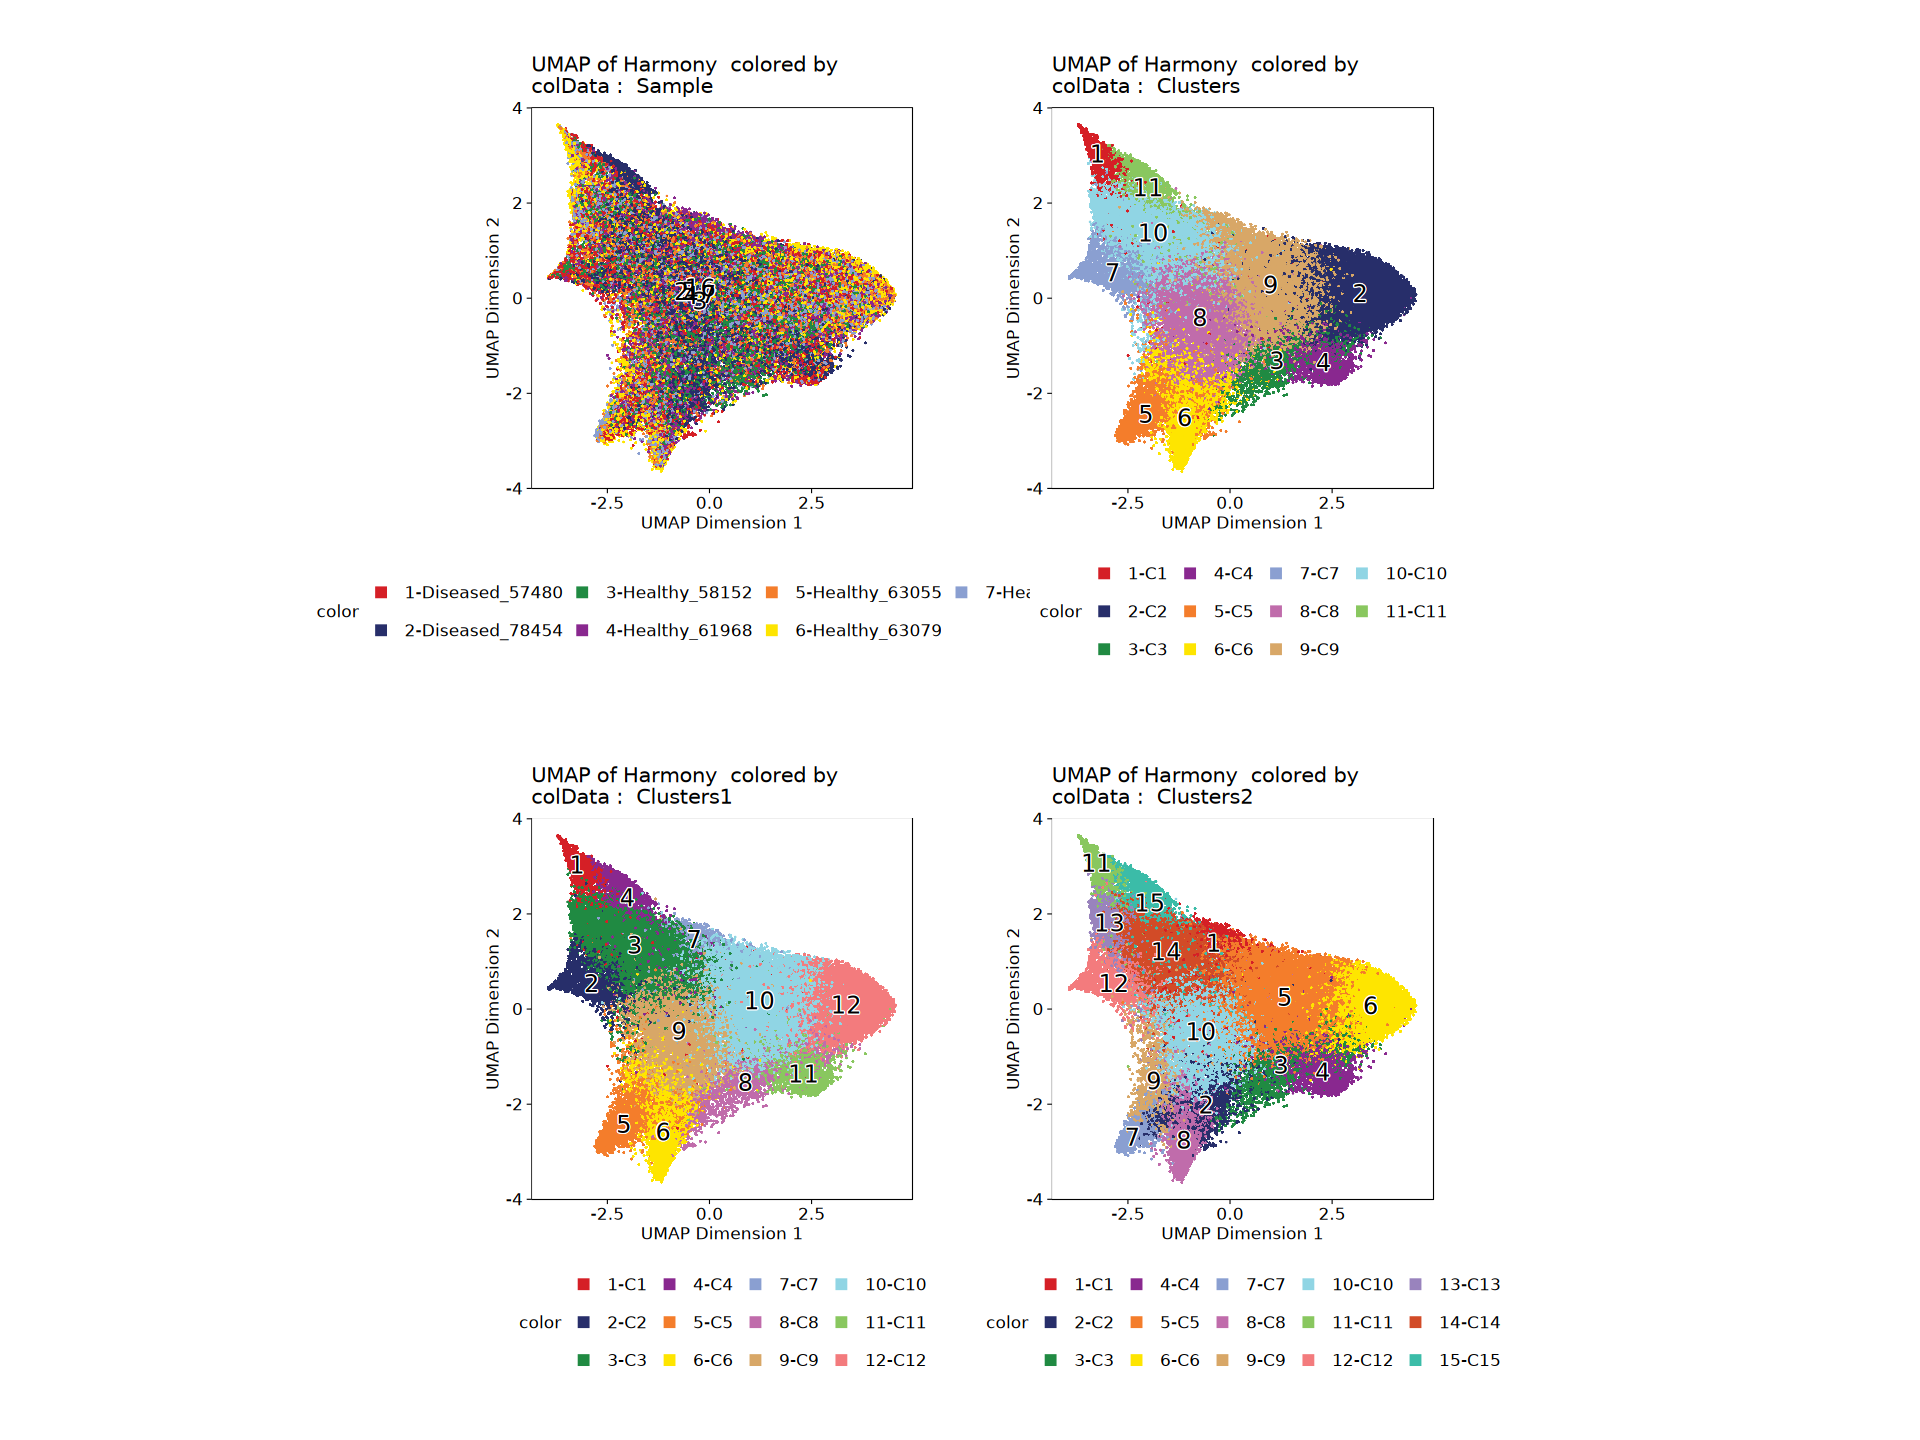

In [14]:
### Plot UMAP and cluster distribution
# plot the UMAP, colored by sample
p1 <- plotEmbedding(
  ArchRProj = proj,
  colorBy = "cellColData",
  name = "Sample",
 embedding = "UMAP", size=1, baseSize=18, labelSize=5, dpi=800
) + theme_ArchR(
  color = "black",
  textFamily = "sans",
  baseSize = 10,
  baseLineSize = 0.5,
  baseRectSize = 0.5,
  plotMarginCm = 1,
  legendPosition = "bottom",
 legendTextSize = 10,
  axisTickCm = 0.1,
 xText90 = FALSE,
  yText90 = FALSE
)

# plot the UMAP, colored by clusters
p2 <- plotEmbedding(
  ArchRProj = proj,
  colorBy = "cellColData",
  name = "Clusters",
  embedding = "UMAP", size=1, baseSize=18, labelSize=5, dpi=800
) + theme_ArchR(
  color = "black",
  textFamily = "sans",
  baseSize = 10,
  baseLineSize = 0.5,
  baseRectSize = 0.5,
  plotMarginCm = 1,
  legendPosition = "bottom",
  legendTextSize = 10,
  axisTickCm = 0.1,
  xText90 = FALSE,
  yText90 = FALSE
)

# plot the UMAP, colored by clusters
p3 <- plotEmbedding(
  ArchRProj = proj,
  colorBy = "cellColData",
  name = "Clusters1",
  embedding = "UMAP", size=1, baseSize=18, labelSize=5, dpi=800
) + theme_ArchR(
  color = "black",
  textFamily = "sans",
  baseSize = 10,
  baseLineSize = 0.5,
  baseRectSize = 0.5,
  plotMarginCm = 1,
  legendPosition = "bottom",
  legendTextSize = 10,
  axisTickCm = 0.1,
  xText90 = FALSE,
  yText90 = FALSE
)

# plot the UMAP, colored by clusters
p4 <- plotEmbedding(
  ArchRProj = proj,
  colorBy = "cellColData",
  name = "Clusters2",
  embedding = "UMAP", size=1, baseSize=18, labelSize=5, dpi=800
) + theme_ArchR(
  color = "black",
  textFamily = "sans",
  baseSize = 10,
  baseLineSize = 0.5,
  baseRectSize = 0.5,
  plotMarginCm = 1,
  legendPosition = "bottom",
  legendTextSize = 10,
  axisTickCm = 0.1,
  xText90 = FALSE,
  yText90 = FALSE
)


options(repr.plot.width=16, repr.plot.height=12)
print(p1 + p2 + p3 + p4)

### Load scRNA-seq data

[1] "2025-12-10 14:18:38 CET"


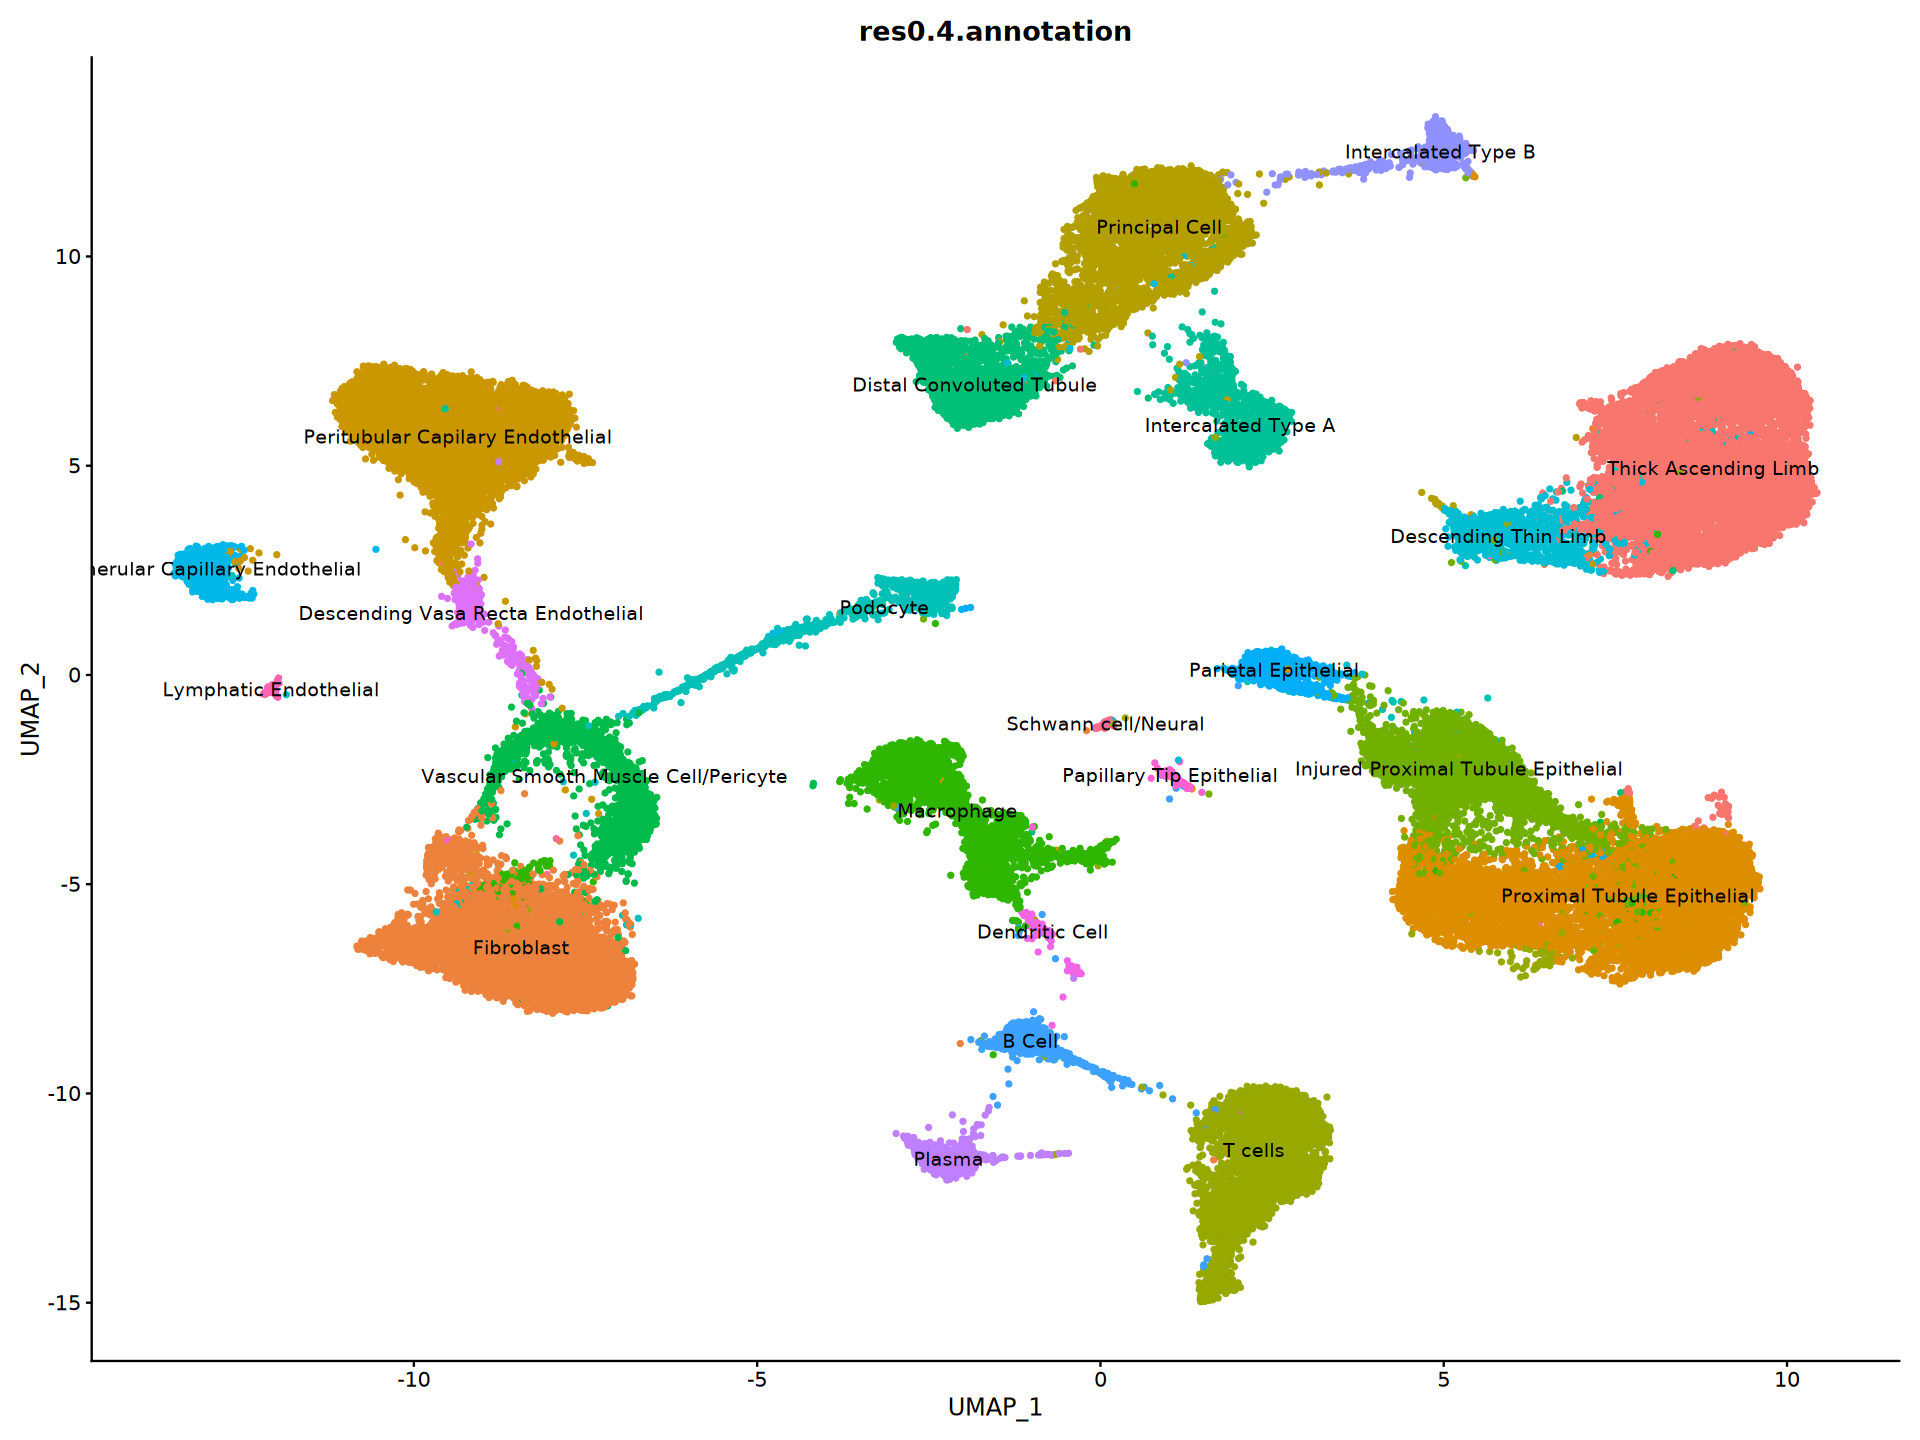

In [15]:
print(Sys.time())
muto_data <- readRDS("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/scRNA/scrna_phase_clustering.rds")
#counts <- GetAssayData(muto_data, assay = "RNA", layer = "counts")
# counts <- as(counts, Class = "Assay5")
#rownames(counts) <- muto_data@assays$RNA@meta.features$feature_name
DimPlot(object = muto_data, group.by = "res0.4.annotation", pt.size = 1, raster=FALSE, label = TRUE) + NoLegend()

In [17]:
#muto_data_raw <- muto_data
#muto_data <- CreateSeuratObject(counts = counts, meta.data = muto_data@meta.data, project="RNA")
proj <- addGeneIntegrationMatrix(
  ArchRProj = proj, 
  useMatrix = "GeneScoreMatrix",
  matrixName = "GeneIntegrationMatrix",
  reducedDims = "Harmony",
  seRNA = muto_data,
  addToArrow = TRUE,
  groupRNA = "res0.4.annotation",
  nameCell = "predictedCell",
  nameGroup = "predictedGroup",
  nameScore = "predictedScore",
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addGeneIntegrationMatrix-4703a61db691d-Date-2025-12-10_Time-14-24-09.351555.log
If there is an issue, please report to github with logFile!

2025-12-10 14:24:09.984652 : Running Seurat's Integration Stuart* et al 2019, 0.011 mins elapsed.

2025-12-10 14:24:10.396571 : Checking ATAC Input, 0.017 mins elapsed.

2025-12-10 14:24:11.934996 : Checking RNA Input, 0.043 mins elapsed.

2025-12-10 14:24:16.140106 : Found 16164 overlapping gene names from gene scores and rna matrix!, 0.113 mins elapsed.

2025-12-10 14:24:16.14632 : Creating Integration Blocks, 0.113 mins elapsed.

2025-12-10 14:24:17.954619 : Prepping Interation Data, 0.143 mins elapsed.

Warning! Not all requested dimsToUse are available! The follow dims were not found in Harmony:
30
Unavailable dims will be automatically excluded...

2025-12-10 14:24:18.771997 : Computing Integration in 6 Integration Blocks!, 0 mins elapsed.

2025-12-10 14:24:18.778112 : Block (1 of 6) : Computing Integration

### Save the integrated object

In [19]:
print(Sys.time())
saveRDS(proj, "/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/data/processed/scATAC/r_objects/kidney7_integrate_scRNA.rds")

[1] "2025-12-10 14:57:42 CET"
